In [21]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import numpy as np
import time
import matplotlib.pyplot as plt

In [22]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=3, padding=1, pool=True):
        super().__init__()
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size, padding=padding)
        self.bn = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(2) if pool else nn.Identity()

    def forward(self, x):
        x = self.conv(x)
        x = self.bn(x)
        x = self.relu(x)
        x = self.pool(x)
        return x


class Model(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            ConvBlock(3, 32),
            ConvBlock(32, 64),
            ConvBlock(64, 128),
            ConvBlock(128, 256),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 2 * 2, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(256, n_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [23]:
transform_train = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)),
])

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)),
])

train_dataset = torchvision.datasets.CIFAR10(
    root='./data', train=True, download=True, transform=transform_train
)
test_dataset = torchvision.datasets.CIFAR10(
    root='./data', train=False, download=True, transform=transform_test
)

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

In [24]:
print(f"train size: {len(train_dataset)} ")
print(f"test size: {len(test_dataset)}")
print('размер картинки - ', train_dataset[0][0].shape)
print('label - ', train_dataset[0][1])

train size: 50000 
test size: 10000
размер картинки -  torch.Size([3, 32, 32])
label -  6


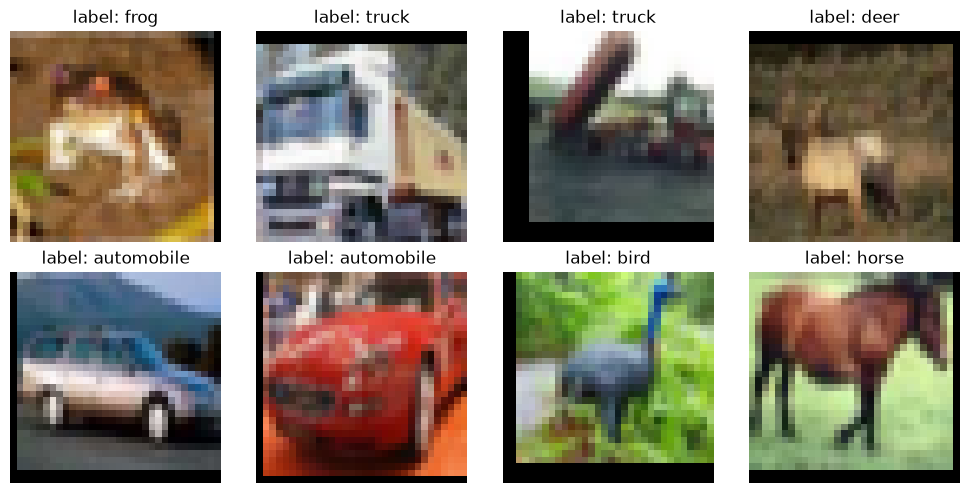

In [25]:
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for ax, idx in zip(axes.ravel(), range(8)):
    img, label = train_dataset[idx]
    img = img * torch.tensor([0.2470, 0.2435, 0.2616]).view(3, 1, 1) + \
          torch.tensor([0.4914, 0.4822, 0.4465]).view(3, 1, 1)
    ax.imshow(img.permute(1, 2, 0).clamp(0, 1).numpy())
    ax.set_title(f"label: {class_names[label]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [26]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'device - {device}')

epochs = 60
batch_size = 128
learning_rate = 0.1

train_loader = torch.utils.data.DataLoader(
    train_dataset, batch_size=batch_size, shuffle=True, num_workers=2
)
test_loader = torch.utils.data.DataLoader(
    test_dataset, batch_size=batch_size, shuffle=False, num_workers=2
)

model = Model().to(device)
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=learning_rate,
    momentum=0.9,
    weight_decay=5e-4,
    nesterov=True,
)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=epochs, eta_min=1e-4
)

print(model)

device - cuda
Model(
  (features): Sequential(
    (0): ConvBlock(
      (conv): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (bn): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU()
      (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): ConvBlock(
      (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (bn): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU()
      (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): ConvBlock(
      (conv): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (bn): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU()
      (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
 

In [27]:
def evaluate(loader):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            logits = model(images)
            loss = criterion(logits, labels)
            total_loss += loss.item() * images.size(0)
            correct += (logits.argmax(dim=1) == labels).sum().item()
            total += images.size(0)
    return total_loss / total, correct / total

In [28]:
history = {'train_loss': [], 'train_acc': [], 'test_loss': [], 'test_acc': [], 'lr': []}

for epoch in range(1, epochs + 1):
    start_time = time.perf_counter()
    model.train()
    train_loss, train_correct, train_total = 0.0, 0, 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        logits = model(images)
        loss = criterion(logits, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        train_correct += (logits.argmax(dim=1) == labels).sum().item()
        train_total += images.size(0)

    train_loss /= train_total
    train_accuracy = train_correct / train_total
    test_loss, test_accuracy = evaluate(test_loader)

    current_lr = optimizer.param_groups[0]['lr']
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_accuracy)
    history['test_loss'].append(test_loss)
    history['test_acc'].append(test_accuracy)
    history['lr'].append(current_lr)

    scheduler.step()

    end_time = time.perf_counter()
    execution_time = end_time - start_time

    print(f'{epoch} epoch  loss - {train_loss:0.3f}   time - {execution_time:0.3f} sec  '
          f'train_accuracy - {train_accuracy:0.3f}  test_loss - {test_loss:0.3f}  '
          f'test_accuracy - {test_accuracy:0.3f}  lr - {current_lr:.5f}')

1 epoch  loss - 2.089   time - 24.862 sec  train_accuracy - 0.196  test_loss - 1.872  test_accuracy - 0.257  lr - 0.10000
2 epoch  loss - 1.899   time - 23.996 sec  train_accuracy - 0.269  test_loss - 1.561  test_accuracy - 0.382  lr - 0.09993
3 epoch  loss - 1.510   time - 23.080 sec  train_accuracy - 0.434  test_loss - 1.236  test_accuracy - 0.558  lr - 0.09973
4 epoch  loss - 1.226   time - 22.005 sec  train_accuracy - 0.570  test_loss - 1.088  test_accuracy - 0.620  lr - 0.09939
5 epoch  loss - 1.079   time - 21.951 sec  train_accuracy - 0.629  test_loss - 1.196  test_accuracy - 0.618  lr - 0.09891
6 epoch  loss - 0.973   time - 22.023 sec  train_accuracy - 0.674  test_loss - 0.926  test_accuracy - 0.683  lr - 0.09830
7 epoch  loss - 0.906   time - 22.165 sec  train_accuracy - 0.697  test_loss - 0.840  test_accuracy - 0.712  lr - 0.09756
8 epoch  loss - 0.856   time - 22.145 sec  train_accuracy - 0.715  test_loss - 0.819  test_accuracy - 0.722  lr - 0.09668
9 epoch  loss - 0.832   

In [29]:
test_loss, test_accuracy = evaluate(test_loader)
print(f'test loss - {test_loss:0.3f}')
print(f'test_accuracy - {test_accuracy:.4f}')

test loss - 0.350
test_accuracy - 0.8888


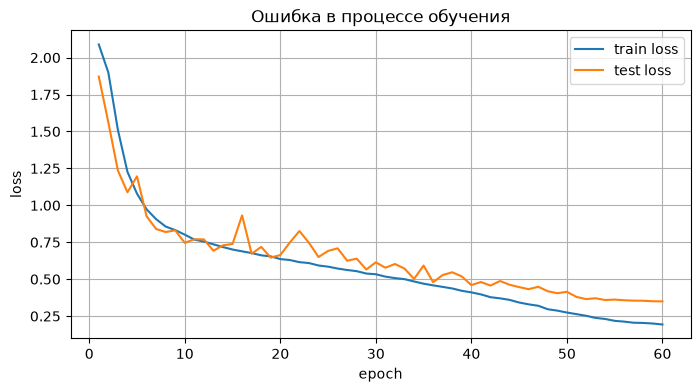

In [30]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, epochs + 1), history['train_loss'], label='train loss')
plt.plot(range(1, epochs + 1), history['test_loss'], label='test loss')
plt.xlabel('epoch')
plt.ylabel('loss')
plt.title('Ошибка в процессе обучения')
plt.grid(True)
plt.legend()
plt.show()

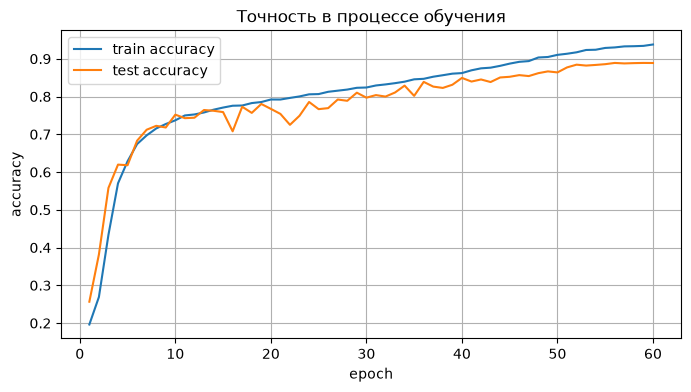

In [31]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, epochs + 1), history['train_acc'], label='train accuracy')
plt.plot(range(1, epochs + 1), history['test_acc'], label='test accuracy')
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.title('Точность в процессе обучения')
plt.grid(True)
plt.legend()
plt.show()

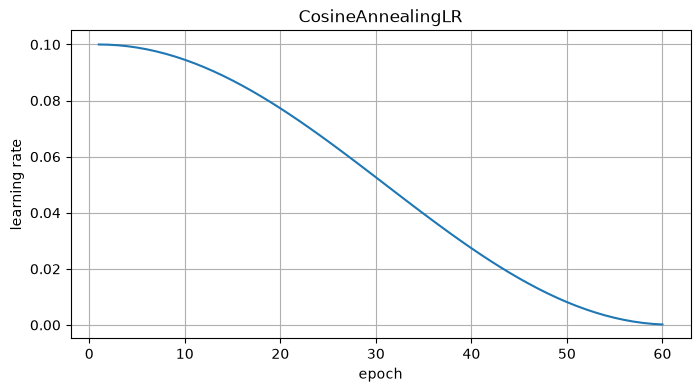

In [32]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, epochs + 1), history['lr'])
plt.xlabel('epoch')
plt.ylabel('learning rate')
plt.title('CosineAnnealingLR')
plt.grid(True)
plt.show()